In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, classification_report

FUNCTIONS

In [23]:
def plot_series_interactive(df, columns, window=None, center=True,
                            labels=None, title=None, ylabel=""):
    """Interactive line plot of monthly columns.

    window=None  -> raw monthly values
    window=12    -> rolling mean over 12 months
    """
    if isinstance(columns, str):
        columns = [columns]
    labels = labels or {}

    d = df.sort_values("month").copy()
    names = []
    for col in columns:
        base = labels.get(col, col)
        if window:
            name = f"{base} ({window}-month mean)"
            d[name] = d[col].rolling(window, center=center).mean()
        else:
            name = base
            d[name] = d[col]
        names.append(name)

    long = d.melt(id_vars="month", value_vars=names,
                  var_name="series", value_name="value")

    fig = px.line(long, x="month", y="value", color="series",
                  title=title, labels={"value": ylabel, "month": ""})
    fig.update_traces(hovertemplate="%{y:.2f}<extra>%{fullData.name}</extra>")
    fig.update_layout(hovermode="x unified", height=420, legend_title_text="")
    fig.update_xaxes(hoverformat="%b %Y", rangeslider_visible=True)
    fig.show()

In [3]:
# def show_quinquennial_temperature_tendencies(df)

#### Paths

In [4]:
power_folder = '../data/processed/power_dataset/'

## 1. Individual EDAs

### 1.1 Écija region

#### NASA/POWER Source Native Resolution Daily Data 

NASA/POWER Source Native Resolution Daily Data 
Dates (month/day/year): 01/01/1981 through 10/31/2026 in UTC

In [5]:
écija_power_monthly_path = os.path.join(power_folder, 'monthly/écija_monthly.csv')
écija_power_daily_path = os.path.join(power_folder, 'daily/écija_daily.csv')
écija_monthly = pd.read_csv(écija_power_monthly_path)
écija_daily = pd.read_csv(écija_power_daily_path)

In [6]:
écija_monthly.columns

Index(['month', 't2m_mean', 't2m_max_mean', 't2m_max_peak', 't2m_min_mean',
       't2m_min_low', 'precip_mm', 'rain_days', 'rh_mean', 'wind_mean',
       'soil_root_mean', 'soil_top_mean', 'frost_days', 'heat_days',
       'valid_days'],
      dtype='str')

#### 1.1.1 Long-term trend: 12-month rolling mean of temperature, 1981-2026

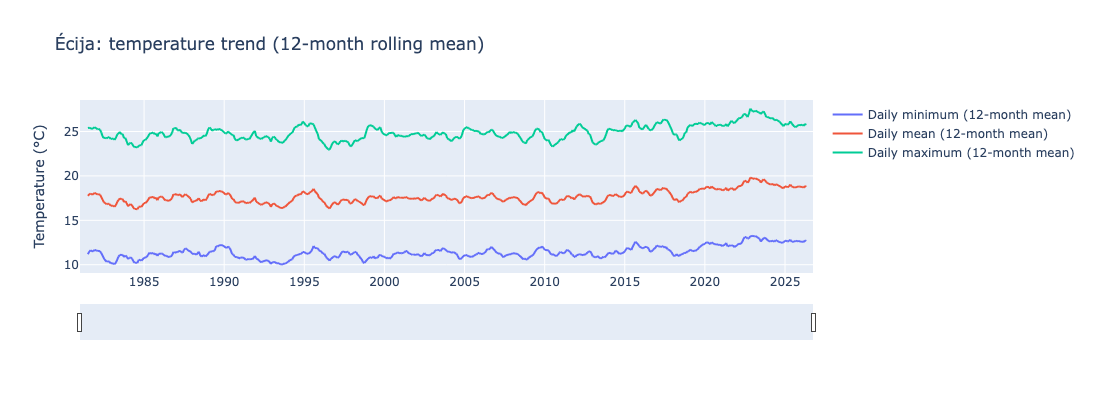

In [25]:
plot_series_interactive(
    écija_monthly,
    ["t2m_min_mean", "t2m_mean", "t2m_max_mean"],
    12,
    labels={"t2m_min_mean": "Daily minimum", "t2m_mean": "Daily mean", "t2m_max_mean": "Daily maximum"},
    title="Écija: temperature trend (12-month rolling mean)",
    ylabel="Temperature (°C)",
)

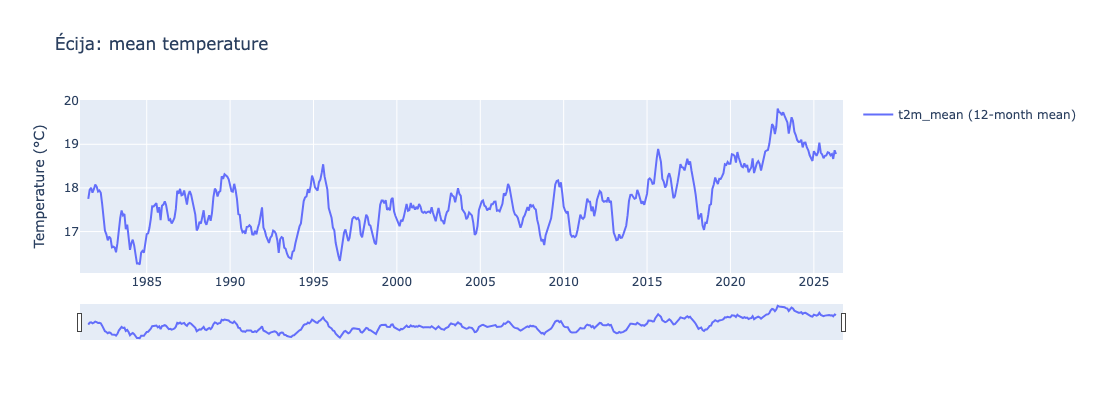

In [26]:
plot_series_interactive(écija_monthly, "t2m_mean",12, title="Écija: mean temperature (12-month rolling mean)", ylabel="Temperature (°C)")

**Conclusion:** The 12-month mean stays around 17-18 °C through the 80s, 90s and 2000s, with dips in the early 80s, 1993-96 and 2012. After 2020 it moves up to about 19-19.5 °C and peaks around 2022-23. Highs and lows rise together, so the whole range shifts and it isn't only hotter summers.

#### 1.1.2 Monthly temperature series, 1981-2026 (unsmoothed)

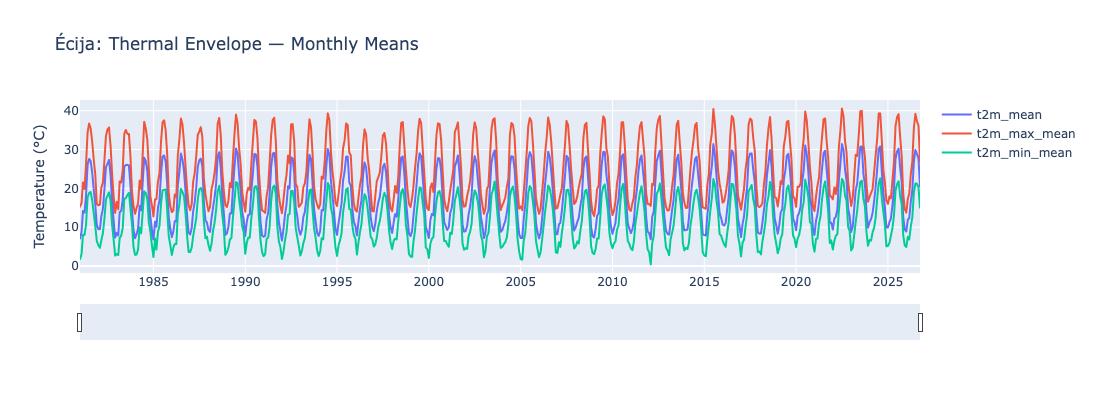

In [28]:
plot_series_interactive(écija_monthly, ['t2m_mean', 't2m_max_mean', 't2m_min_mean'], title="Écija: Thermal Envelope — Monthly Means", ylabel="Temperature (°C)")

#### 1.1.3 Monthly temperature extremes, 1981-2026 (unsmoothed)

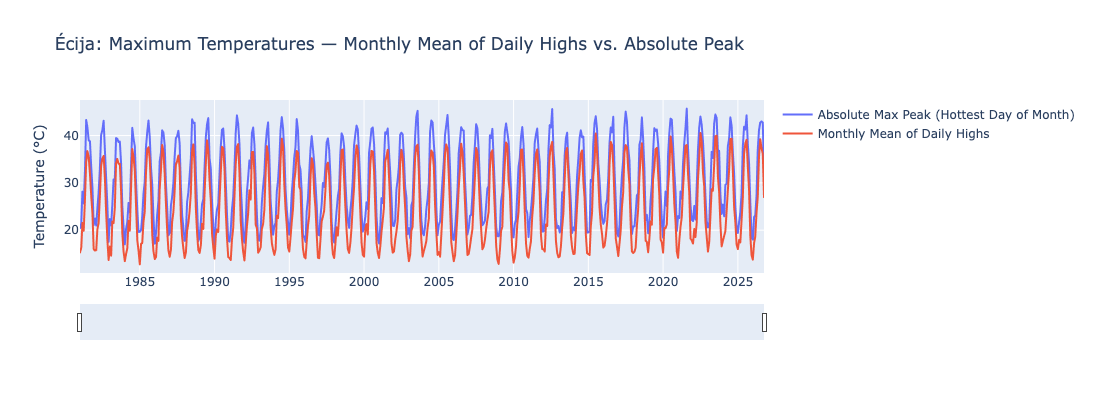

In [33]:
plot_series_interactive(écija_monthly, ['t2m_max_peak','t2m_max_mean'], title="Écija: Maximum Temperatures — Monthly Mean of Daily Highs vs. Absolute Peak", ylabel="Temperature (°C)",labels={
        't2m_max_peak': 'Absolute Max Peak (Hottest Day of Month)',
        't2m_max_mean': 'Monthly Mean of Daily Highs'
    })

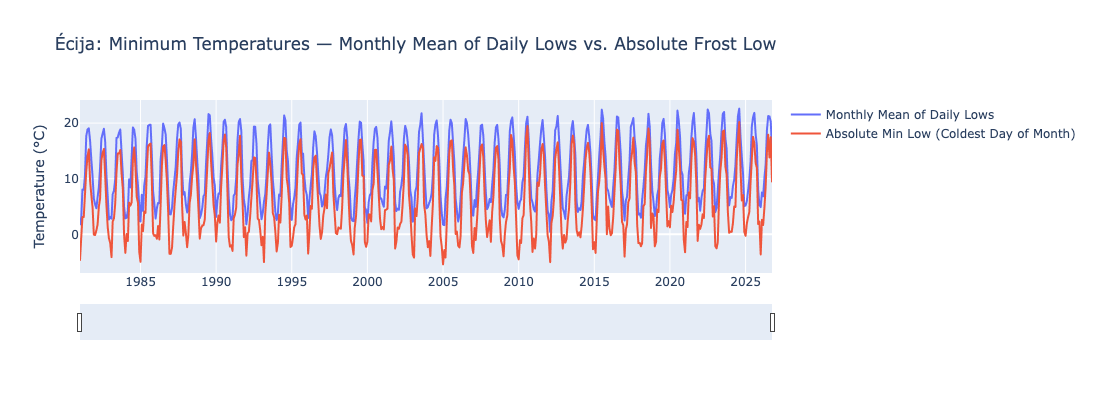

In [34]:
plot_series_interactive(
    df=écija_monthly,
    columns=['t2m_min_mean', 't2m_min_low'],
    title="Écija: Minimum Temperatures — Monthly Mean of Daily Lows vs. Absolute Min Low",
    ylabel="Temperature (°C)",
    labels={
        't2m_min_mean': 'Monthly Mean of Daily Lows',
        't2m_min_low': 'Absolute Min Low (Coldest Day of Month)'
    }
)

**Conclusion:** The hottest day of the month reaches about 43-46 °C in summer in most years, while the monthly mean of daily highs stays around 37-40 °C. The two lines are only a few degrees apart, so extreme heat here is a regular feature of summer and not rare spikes.

### 1.2 Guadix region

#### NASA/POWER Source Native Resolution Daily Data 

Dates (month/day/year): 01/01/1981 through 10/31/2026 in UTC

In [9]:
guadix_power_monthly_path = os.path.join(power_folder, 'monthly/guadix_monthly.csv')
guadix_power_daily_path = os.path.join(power_folder, 'daily/guadix_daily.csv')
guadix_monthly = pd.read_csv(guadix_power_monthly_path)
guadix_daily = pd.read_csv(guadix_power_daily_path)

In [10]:
guadix_monthly.columns

Index(['month', 't2m_mean', 't2m_max_mean', 't2m_max_peak', 't2m_min_mean',
       't2m_min_low', 'precip_mm', 'rain_days', 'rh_mean', 'wind_mean',
       'soil_root_mean', 'soil_top_mean', 'frost_days', 'heat_days',
       'valid_days'],
      dtype='str')

#### 1.2.1 Long-term trend: 12-month rolling mean of temperature, 1981-2026

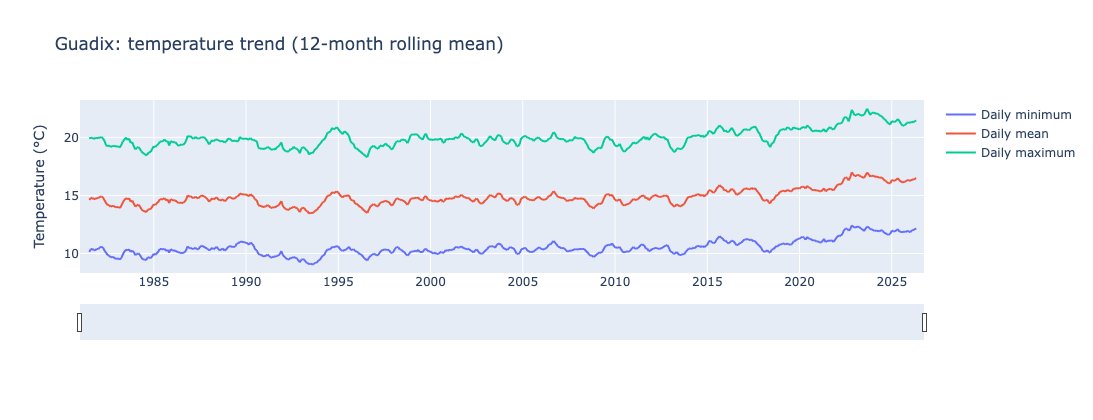

In [22]:
plot_series_interactive(
    guadix_monthly,
    ["t2m_min_mean", "t2m_mean", "t2m_max_mean"],
    12,
    labels={"t2m_min_mean": "Daily minimum", "t2m_mean": "Daily mean", "t2m_max_mean": "Daily maximum"},
    title="Guadix: temperature trend (12-month rolling mean)",
    ylabel="Temperature (°C)",
)

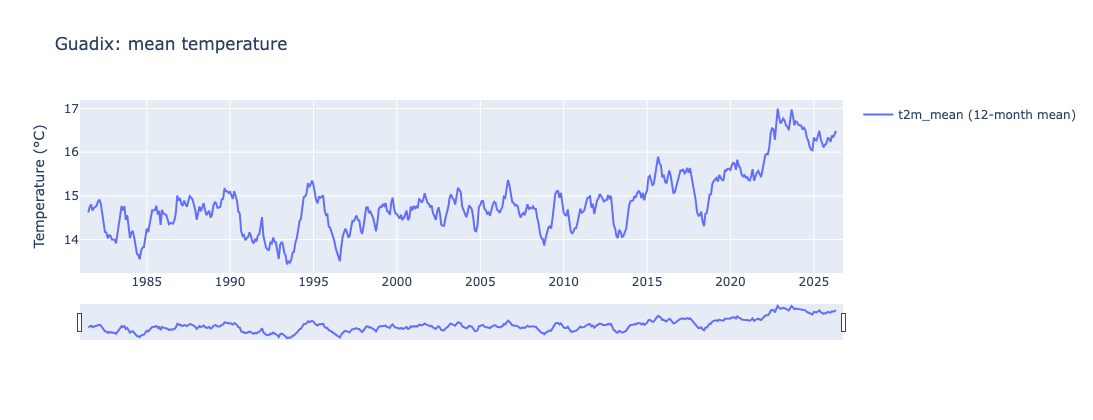

In [12]:
plot_series_interactive(guadix_monthly, "t2m_mean",12, title="Guadix: mean temperature", ylabel="Temperature (°C)")

**Conclusion:** Mean temperature goes from roughly 14.5 °C in the 80s to about 16-17 °C in recent years. As in Écija, most of the rise happens after 2015, with a peak around 2022-23. It is the coolest of the four zones all the way through.

#### 1.2.2 Monthly temperature series, 1981-2026 (unsmoothed)

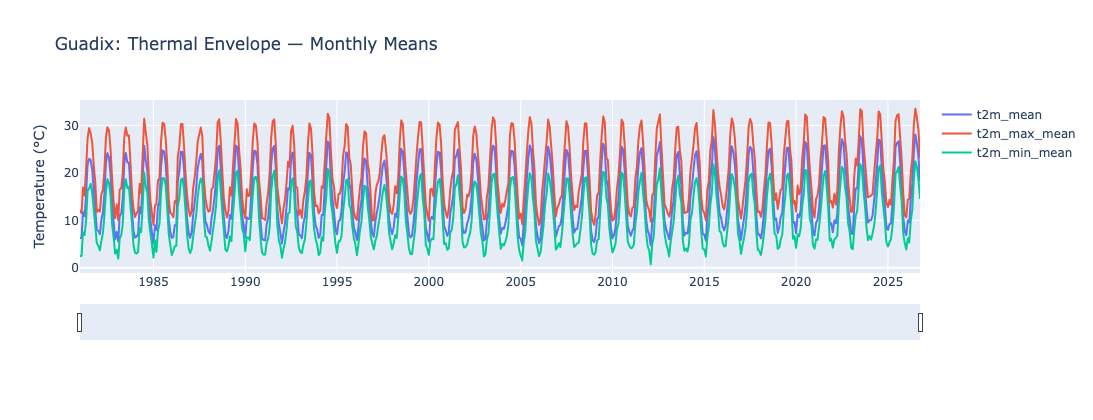

In [36]:
plot_series_interactive(guadix_monthly, ['t2m_mean', 't2m_max_mean', 't2m_min_mean'], title="Guadix: Thermal Envelope — Monthly Means", ylabel="Temperature (°C)")

#### 1.2.3 Monthly temperature extremes, 1981-2026 (unsmoothed)

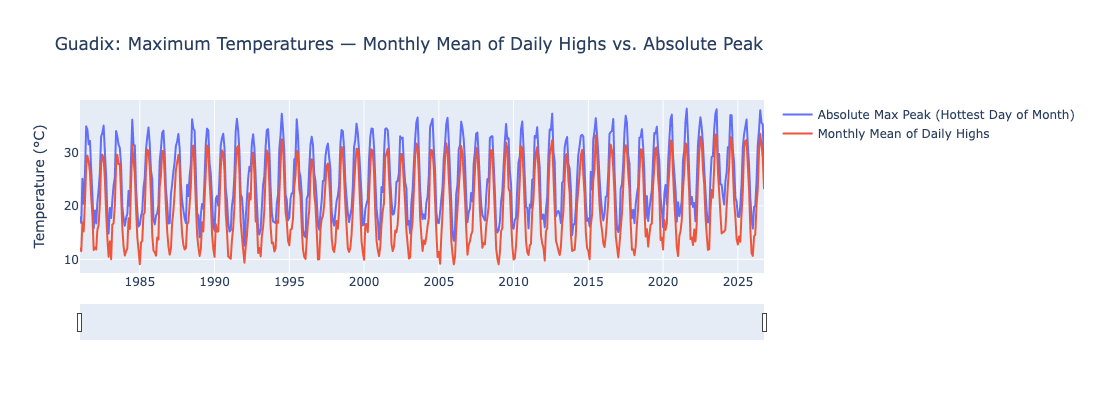

In [40]:
plot_series_interactive(guadix_monthly, ['t2m_max_peak','t2m_max_mean'], title="Guadix: Maximum Temperatures — Monthly Mean of Daily Highs vs. Absolute Peak", ylabel="Temperature (°C)",labels={
        't2m_max_peak': 'Absolute Max Peak (Hottest Day of Month)',
        't2m_max_mean': 'Monthly Mean of Daily Highs'
    })

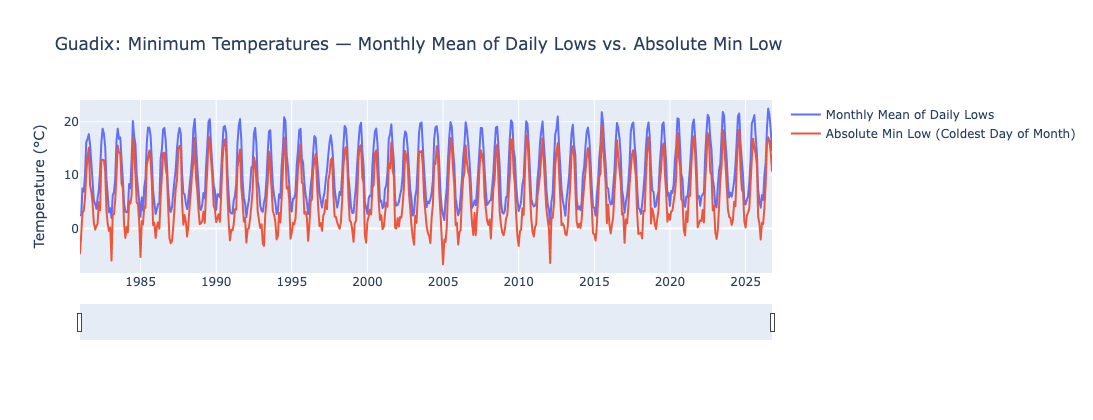

In [43]:
plot_series_interactive(
    df=guadix_monthly,
    columns=['t2m_min_mean', 't2m_min_low'],
    title="Guadix: Minimum Temperatures — Monthly Mean of Daily Lows vs. Absolute Min Low",
    ylabel="Temperature (°C)",
    labels={
        't2m_min_mean': 'Monthly Mean of Daily Lows',
        't2m_min_low': 'Absolute Min Low (Coldest Day of Month)'
    }
)

**Conclusion:** Frost is a real thing here. The coldest night of the month drops below 0 °C in most winters and reaches about -6 or -7 °C in a few of them (around 2005 and 2012, check exact years with idxmin). Summer lows are still quite warm for a highland, which I would treat with caution (see limitations).

### 1.3 Jerez region

#### NASA/POWER Source Native Resolution Daily Data 

Dates (month/day/year): 01/01/1981 through 10/31/2026 in UTC

In [13]:
jerez_power_monthly_path = os.path.join(power_folder, 'monthly/jerez_monthly.csv')
jerez_power_daily_path = os.path.join(power_folder, 'daily/jerez_daily.csv')
jerez_monthly = pd.read_csv(jerez_power_monthly_path)
jerez_daily = pd.read_csv(jerez_power_daily_path)

In [14]:
jerez_monthly.columns

Index(['month', 't2m_mean', 't2m_max_mean', 't2m_max_peak', 't2m_min_mean',
       't2m_min_low', 'precip_mm', 'rain_days', 'rh_mean', 'wind_mean',
       'soil_root_mean', 'soil_top_mean', 'frost_days', 'heat_days',
       'valid_days'],
      dtype='str')

#### 1.3.1 Long-term trend: 12-month rolling mean of temperature, 1981-2026

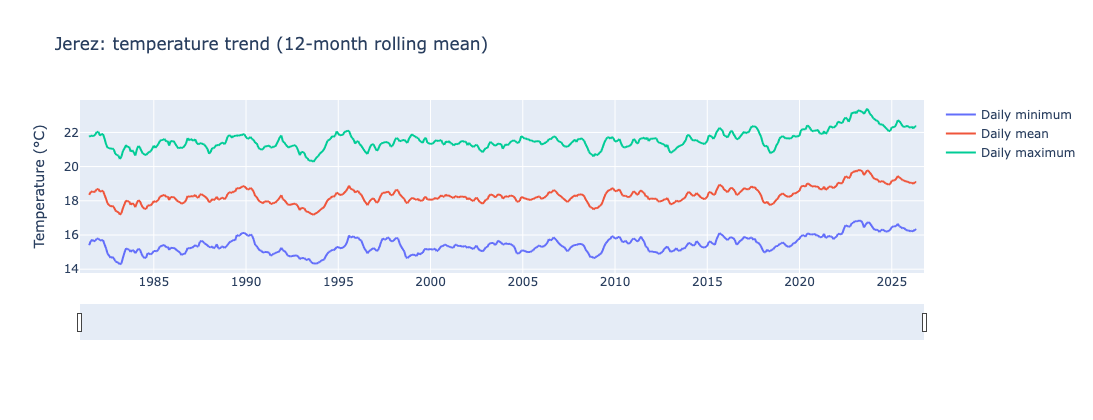

In [15]:
plot_series_interactive(
    jerez_monthly,
    ["t2m_min_mean", "t2m_mean", "t2m_max_mean"],
    12,
    labels={"t2m_min_mean": "Daily minimum", "t2m_mean": "Daily mean", "t2m_max_mean": "Daily maximum"},
    title="Jerez: temperature trend (12-month rolling mean)",
    ylabel="Temperature (°C)",
)

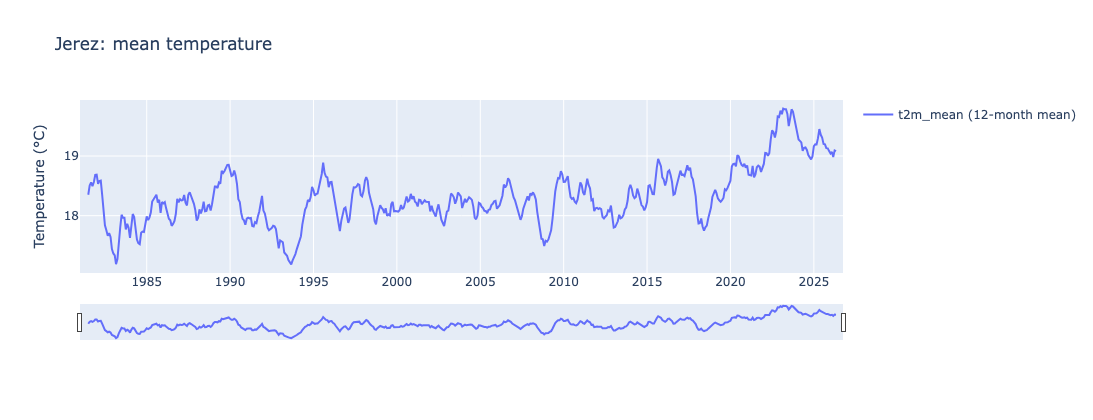

In [16]:
plot_series_interactive(jerez_monthly, "t2m_mean",12, title="Jerez: mean temperature", ylabel="Temperature (°C)")

**Conclusion:** Mean temperature is about 18 °C early in the record and 19-19.5 °C after 2020. The rise is smaller than in Guadix and Úbeda. The gap between the daily maximum and minimum lines is the narrowest of the four zones.

#### 1.3.2 Monthly temperature series, 1981-2026 (unsmoothed)

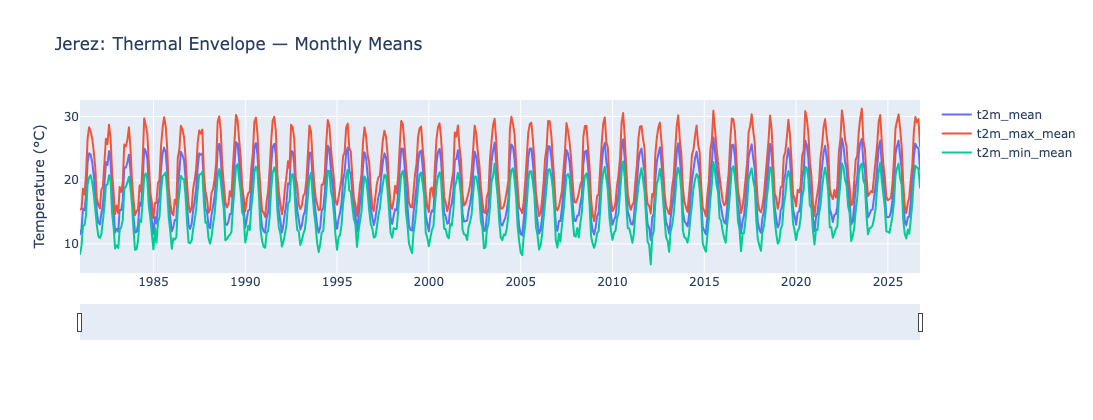

In [37]:
plot_series_interactive(jerez_monthly, ['t2m_mean', 't2m_max_mean', 't2m_min_mean'], title="Jerez: Thermal Envelope — Monthly Means", ylabel="Temperature (°C)")

#### 1.3.3 Monthly temperature extremes, 1981-2026 (unsmoothed)

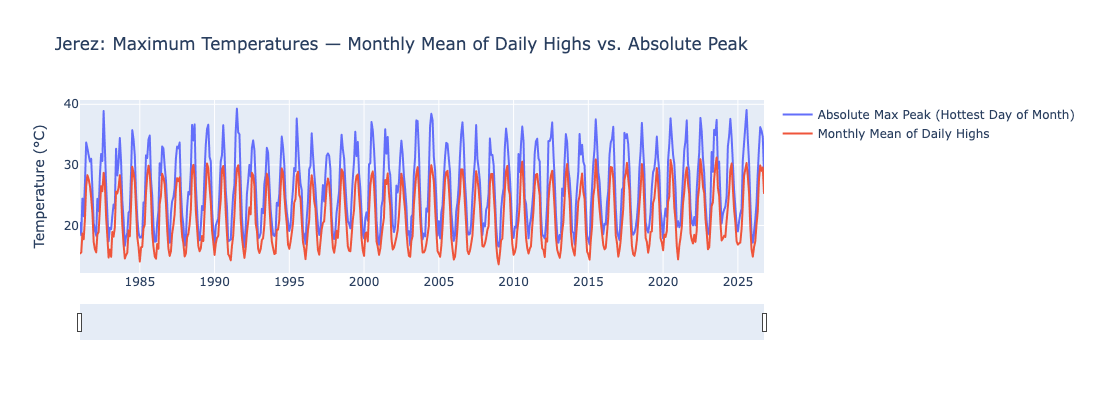

In [41]:
plot_series_interactive(jerez_monthly, ['t2m_max_peak','t2m_max_mean'], title="Jerez: Maximum Temperatures — Monthly Mean of Daily Highs vs. Absolute Peak", ylabel="Temperature (°C)",labels={
        't2m_max_peak': 'Absolute Max Peak (Hottest Day of Month)',
        't2m_max_mean': 'Monthly Mean of Daily Highs'
    })

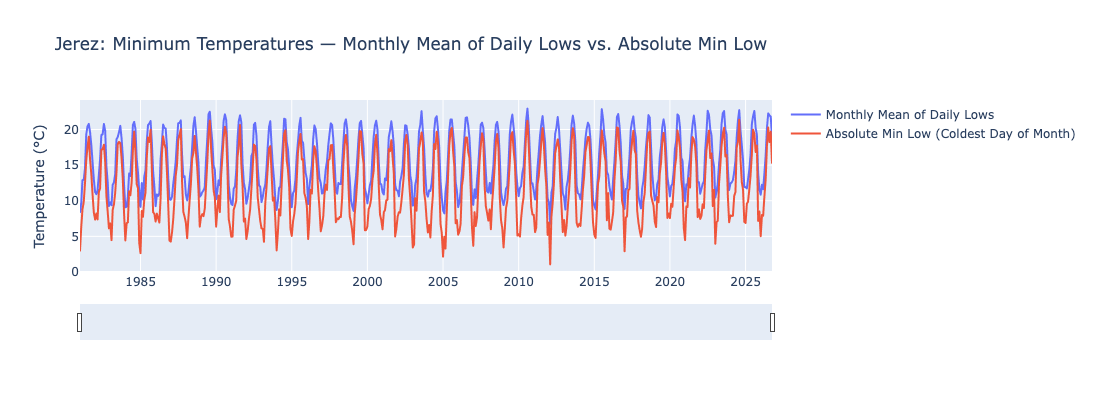

In [44]:
plot_series_interactive(
    df=jerez_monthly,
    columns=['t2m_min_mean', 't2m_min_low'],
    title="Jerez: Minimum Temperatures — Monthly Mean of Daily Lows vs. Absolute Min Low",
    ylabel="Temperature (°C)",
    labels={
        't2m_min_mean': 'Monthly Mean of Daily Lows',
        't2m_min_low': 'Absolute Min Low (Coldest Day of Month)'
    }
)

**Conclusion:** Jerez is the mild one. The coldest night rarely goes below 5 °C, and the lowest value in the whole record is around 1 °C (about 2012), so frost is practically not an issue. The hottest days reach about 35-39 °C, several degrees under Écija.

### 1.4 Úbeda region

#### NASA/POWER Source Native Resolution Daily Data 

Dates (month/day/year): 01/01/1981 through 10/31/2026 in UTC

In [17]:
úbeda_power_monthly_path = os.path.join(power_folder, 'monthly/úbeda_monthly.csv')
úbeda_power_daily_path = os.path.join(power_folder, 'daily/úbeda_daily.csv')
úbeda_monthly = pd.read_csv(úbeda_power_monthly_path)
úbeda_daily = pd.read_csv(úbeda_power_daily_path)

In [18]:
úbeda_monthly.columns

Index(['month', 't2m_mean', 't2m_max_mean', 't2m_max_peak', 't2m_min_mean',
       't2m_min_low', 'precip_mm', 'rain_days', 'rh_mean', 'wind_mean',
       'soil_root_mean', 'soil_top_mean', 'frost_days', 'heat_days',
       'valid_days'],
      dtype='str')

#### 1.4.1 Long-term trend: 12-month rolling mean of temperature, 1981-2026

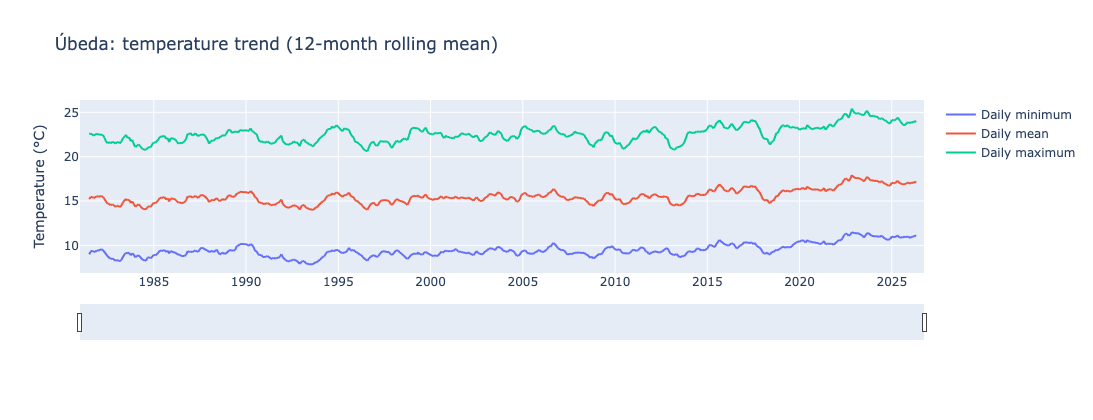

In [19]:
plot_series_interactive(
    úbeda_monthly,
    ["t2m_min_mean", "t2m_mean", "t2m_max_mean"],
    12,
    labels={"t2m_min_mean": "Daily minimum", "t2m_mean": "Daily mean", "t2m_max_mean": "Daily maximum"},
    title="Úbeda: temperature trend (12-month rolling mean)",
    ylabel="Temperature (°C)",
)

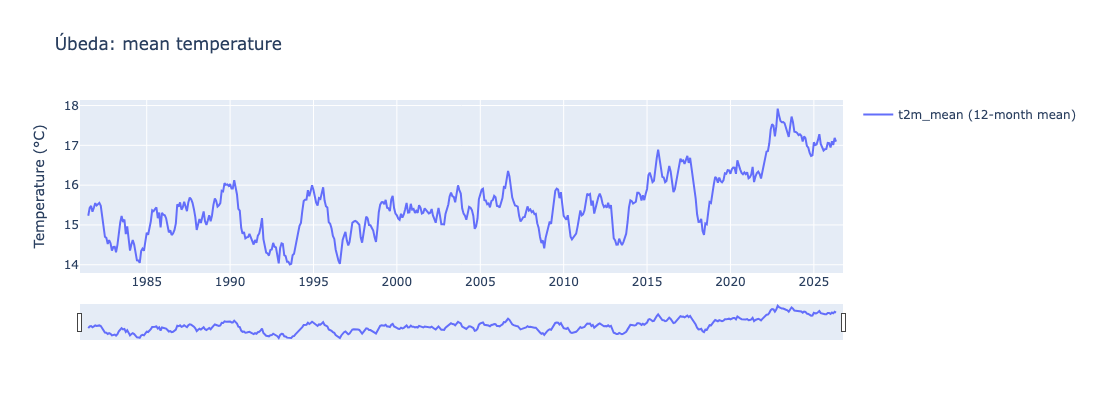

In [38]:
plot_series_interactive(úbeda_monthly, "t2m_mean",12, title="Úbeda: mean temperature", ylabel="Temperature (°C)")

**Conclusion:** Mean temperature moves from about 15-15.5 °C to 17-17.5 °C, with the jump after 2020 again. It sits between Écija and Guadix, closer to Guadix.

#### 1.4.2 Monthly temperature series, 1981-2026 (unsmoothed)

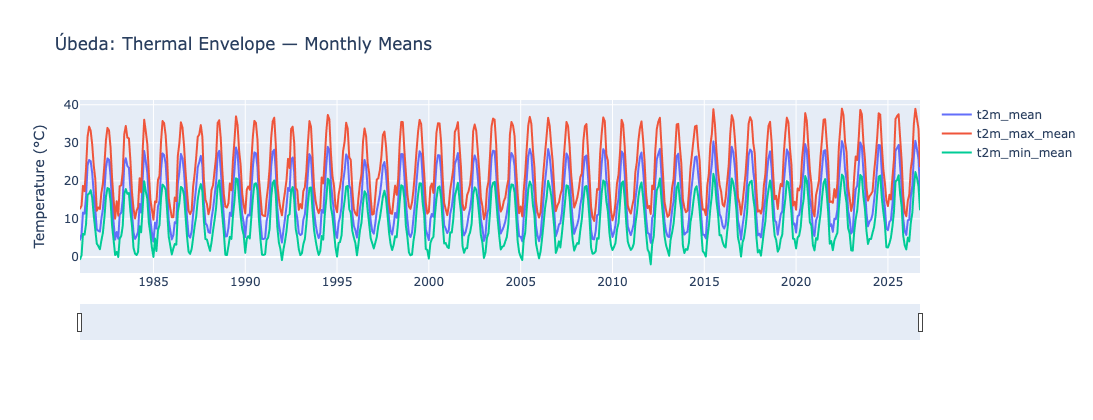

In [39]:
plot_series_interactive(úbeda_monthly, ['t2m_mean', 't2m_max_mean', 't2m_min_mean'], title="Úbeda: Thermal Envelope — Monthly Means", ylabel="Temperature (°C)")

#### 1.4.3 Monthly temperature extremes, 1981-2026 (unsmoothed)

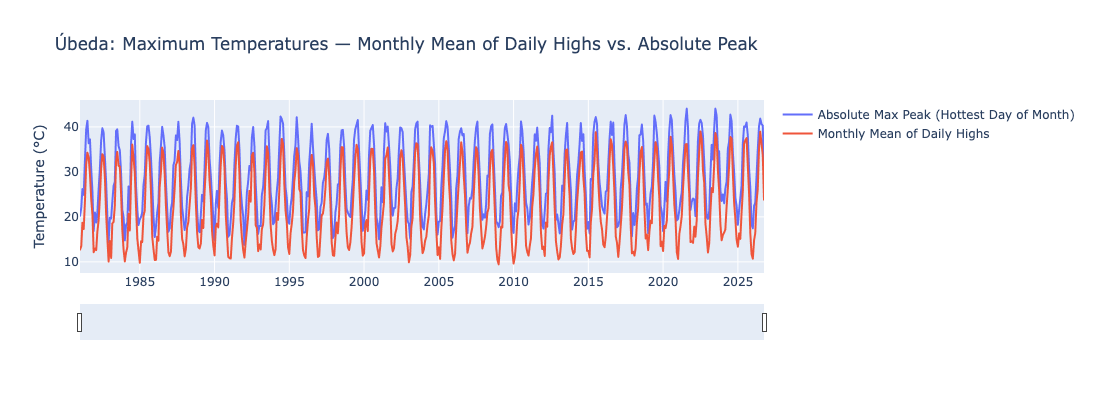

In [42]:
plot_series_interactive(úbeda_monthly, ['t2m_max_peak','t2m_max_mean'], title="Úbeda: Maximum Temperatures — Monthly Mean of Daily Highs vs. Absolute Peak", ylabel="Temperature (°C)",labels={
        't2m_max_peak': 'Absolute Max Peak (Hottest Day of Month)',
        't2m_max_mean': 'Monthly Mean of Daily Highs'
    })

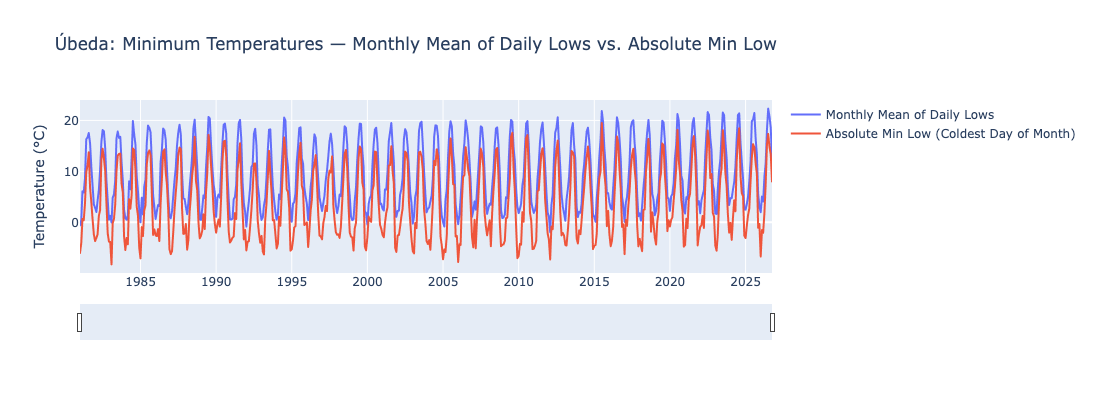

In [45]:
plot_series_interactive(
    df=úbeda_monthly,
    columns=['t2m_min_mean', 't2m_min_low'],
    title="Úbeda: Minimum Temperatures — Monthly Mean of Daily Lows vs. Absolute Min Low",
    ylabel="Temperature (°C)",
    labels={
        't2m_min_mean': 'Monthly Mean of Daily Lows',
        't2m_min_low': 'Absolute Min Low (Coldest Day of Month)'
    }
)

**Conclusion:** Winters are cold like in Guadix. The coldest night is below 0 °C in almost every winter and gets to about -6 or -7 °C in the worst ones. This matters for olive groves, because frost is one of the risks the farmer has to think about.

#### 1.5 Comparison of the four zones
The zones order the same way in every chart: Écija and Jerez at about 18-19 °C, Úbeda around 16, Guadix around 15. The wiggles are almost identical in all four (dips in 1984, 1993-96, 2012 and 2018, a jump after 2020), so POWER is mostly showing one regional signal with a different offset per zone. What separates the zones is the daily range: roughly 13 °C in Écija and Úbeda, about 9-10 in Guadix and only about 6 in Jerez, which fits a more maritime climate. A smaller range in Guadix than in Écija is odd for a highland and may come from the coarse grid averaging a lower altitude, so this goes in the limitations.